# DCLC Expense & Job-Costing Analysis — 2026
**Solar Shrestha-Greene** · Deep Creek Lake Concierge (property field-support and vacation services, Deep Creek Lake, MD)

**Goal:** find out where the business's money goes, and whether the expense log can answer the question owners care about most: *what does each client cost us to serve?*

**Data:** the DCLC Vehicle & Expense Log (a phone form that writes to a Google Sheet), Jan 23 – Oct 31, 2026: 137 purchases, 16 business meals, 14 trips and 1 fuel fill-up. Private client names are replaced with *Client A, B, C…*; receipt links and addresses are removed.

**Questions**
1. What does the business spend money on?
2. How does spending change through the year?
3. Can spending be tied to a client (job costing)?
4. What do trips and meals add?
5. How clean is the data, and what should change in the log?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ORANGE, NAVY, GREY = "#f08a3c", "#0b1324", "#cbd5e1"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

purchases = pd.read_csv("purchases_raw.csv", parse_dates=["date", "entered_on"])
meals     = pd.read_csv("meals_raw.csv", parse_dates=["date", "entered_on"])
trips     = pd.read_csv("trips_raw.csv", parse_dates=["date", "entered_on"])
fuel      = pd.read_csv("fuel_raw.csv", parse_dates=["date"])
rates     = pd.read_csv("mileage_rates.csv", parse_dates=["effective_from"])

for name, d in [("purchases", purchases), ("meals", meals), ("trips", trips), ("fuel", fuel)]:
    print(f"{name:10} {len(d):4} rows   {d['date'].min().date()} to {d['date'].max().date()}")
purchases.head()

purchases   137 rows   2026-01-23 to 2026-10-19
meals        16 rows   2026-06-01 to 2026-10-27
trips        14 rows   2026-10-02 to 2026-10-31
fuel          1 rows   2026-10-25 to 2026-10-25


,date,amount,vendor,category,client,description,has_receipt,entered_on
0,2026-10-16,31.79,Amazon,Supplies,Wild Yough Glamping,Smores station,1,2026-10-17
1,2026-06-30,66.87,Lowes,Supplies,Client A,Mulch and landscaping,1,2026-10-17
2,2026-09-04,33.24,Shopnsave,Supplies,Pine & Paw Lodge,Cleaning supplies,1,2026-10-17
3,2026-09-16,3.18,Dollar Tree,Supplies,Wild Yough Glamping,Toilet papers,1,2026-10-17
4,2026-09-05,16.05,Walmart,Supplies,Client B,Hangers,1,2026-10-17


## Step 1 — Check data quality

Before analyzing anything, check whether the fields can be trusted.

In [2]:
print("Category values (as entered):")
print(purchases["category"].value_counts(), "\n")

print("Vendor spellings (as entered):")
print(purchases["vendor"].value_counts(), "\n")

print("Purchases with no client:", purchases["client"].isna().sum(), "of", len(purchases))
print("Purchases with no receipt:", (purchases["has_receipt"] == 0).sum())
print("Dates entries were typed in:", sorted(purchases["entered_on"].dt.strftime("%b %d").unique()))

Category values (as entered):
category
Supplies             127
Office                 5
Other                  4
Cleaning supplies      1
Name: count, dtype: int64 

Vendor spellings (as entered):
vendor
Amazon             86
Lowe's             32
vista print         6
Walmart             4
Shop N Save         4
Lowes               1
Shopnsave           1
Dollar Tree         1
Tractor supply      1
Mountain postal     1
Name: count, dtype: int64 

Purchases with no client: 108 of 137
Purchases with no receipt: 31
Dates entries were typed in: ['Oct 17', 'Oct 19', 'Oct 20', 'Oct 28']


Three problems stand out:

- **Category is almost useless:** 127 of 137 purchases (93%) are just "Supplies", so it can't show where money goes.
- **Vendor names are inconsistent:** *Lowe's / Lowes*, *Shop N Save / Shopnsave*, *vista print*.
- **The log was filled in after the fact:** every purchase back to January was entered between Oct 17 and Oct 28. The long product titles from Amazon and Lowe's show these came from order history, and those are the rows with no client and (for Lowe's) no receipt.

## Step 2 — Clean the data

In [3]:
# 1. Standardize vendor names (keep the original to count how many needed fixing)
purchases["vendor_raw"] = purchases["vendor"]
vendor_fix = {"lowes": "Lowe's", "lowe's": "Lowe's", "shopnsave": "Shop N Save", "shop n save": "Shop N Save",
              "vista print": "Vistaprint", "tractor supply": "Tractor Supply", "mountain postal": "Mountain Postal"}
purchases["vendor"] = purchases["vendor"].str.strip().str.lower().map(vendor_fix).fillna(purchases["vendor"].str.strip())

# 2. Standardize client names, label blanks
purchases["client"] = purchases["client"].str.strip().str.title().replace({"Dclc": "DCLC (own business)"})
purchases["client"] = purchases["client"].fillna("Not recorded")

# 3. Rebuild a useful category from the item description (first matching rule wins)
rules = [
    ("Events & party decor", "birthday|balloon|wedding|cake|tulle|rose petal|tablecloth|table runner|tea light|"
                             "flower swag|ribbon|glue dot|helium|dollhouse|decor|tip jar|tip bucket|funny birthday"),
    ("Marketing & print",    "rack card|flyer|business card|banner|sticker|note card|car magnet|ballpoint pen|brochure|"
                             "magnetic card|safety vest"),
    ("Equipment & tools",    "pressure wash|surface cleaner|ladder|trimmer|drone|canopy|sidewall|sprayer|hose|"
                             "nozzle|tool belt|coupler|extension wand|fridge|snow shovel|money counter|square terminal|"
                             "eero|router|laminator|tv cart|tablet stand|fan|hammock|sand bag|tips turbo|"
                             "square reader|griddle|high chair"),
    ("Landscaping & garden", "mulch|top soil|boxwood|creeping jenny|edging|plant|cloche|deer|landscape|landscaping"),
    ("Repairs & maintenance","door knob|ice melt|stain|patching|putty|brush|weight"),
    ("Cleaning & guest supplies", "clean|toilet|swiffer|pool shock|kitchen|hanger|propane|batter|smores|"
                             "nightstand|picture hanging"),
    ("Office & storage",     "paper|toner|label tape|file folder|pencil|charging cable|storage bin|tote"),
]
def categorize(desc):
    d = desc.lower()
    for cat, pattern in rules:
        if pd.Series([d]).str.contains(pattern, regex=True).iloc[0]:
            return cat
    return "Uncategorized"
purchases["spend_category"] = purchases["description"].apply(categorize)
print("Uncategorized rows:", (purchases["spend_category"] == "Uncategorized").sum())

# 4. Flag one-off equipment purchases (single item >= $100 in Equipment & tools)
purchases["big_equipment"] = (purchases["spend_category"] == "Equipment & tools") & (purchases["amount"] >= 100)

# 5. Possible duplicates: same day, same vendor, same item
dup = purchases[purchases.duplicated(["date", "vendor", "description", "amount"], keep=False)]
print("\nRepeated identical lines (same day, vendor, item, price):")
print(dup.groupby(["date", "description"]).size().rename("lines"))

purchases["month"] = purchases["date"].dt.to_period("M")
purchases.to_csv("purchases_clean.csv", index=False)

Uncategorized rows: 0

Repeated identical lines (same day, vendor, item, price):
date        description                                                                                  
2026-05-21  2.5-Quart -Quart Babylon Beauty Boxwood Foundation/Hedge Shrub 1 -Pack                           6
2026-07-10  Premium 2 -cu ft Brown Mulch                                                                     2
2026-07-17  Siding and Fence Tintable White Base Solid Exterior Wood Stain and Sealer in One ( 1-gallon )    2
Name: lines, dtype: int64


The repeated lines (6 boxwood shrubs, 2 bags of mulch, 2 gallons of stain) look like real multi-quantity orders, so they stay in.
One pair is a likely **double entry**: a door knob logged on Jan 23 once by hand for Client F ($12.58) and once from Lowe's order history with no client ($11.38).

## Step 3 — Where does the money go?

Total purchases: $6,458.10   (137 items, median $27.55)

                           items    spend  share
spend_category                                  
Equipment & tools             32  3469.99   0.54
Landscaping & garden          23   764.15   0.12
Events & party decor          37   711.48   0.11
Marketing & print             12   576.88   0.09
Cleaning & guest supplies     12   424.46   0.07
Office & storage              12   312.82   0.05
Repairs & maintenance          9   198.32   0.03


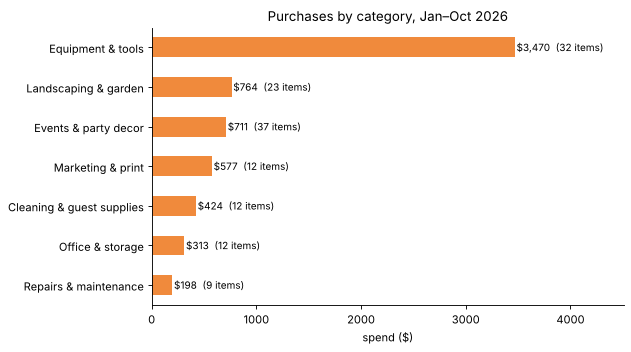

In [4]:
total = purchases["amount"].sum()
by_cat = (purchases.groupby("spend_category")
          .agg(items=("amount", "size"), spend=("amount", "sum"))
          .sort_values("spend", ascending=False))
by_cat["share"] = (by_cat["spend"] / total).round(3)
print(f"Total purchases: ${total:,.2f}   ({len(purchases)} items, median ${purchases['amount'].median():.2f})\n")
print(by_cat.round(2))

ax = by_cat["spend"].sort_values().plot(kind="barh", color=ORANGE, figsize=(8, 4.5))
for i, (v, n) in enumerate(zip(by_cat["spend"].sort_values(), by_cat.loc[by_cat["spend"].sort_values().index, "items"])):
    ax.text(v + 15, i, f"${v:,.0f}  ({n} items)", va="center", fontsize=9)
ax.set_title("Purchases by category, Jan–Oct 2026"); ax.set_xlabel("spend ($)"); ax.set_ylabel("")
ax.set_xlim(0, by_cat["spend"].max() * 1.3)
plt.tight_layout(); plt.savefig("spend_by_category.png", dpi=110); plt.show()

In [5]:
big = purchases[purchases["big_equipment"]].sort_values("amount", ascending=False)
print(f"{len(big)} equipment purchases of $100+ = ${big['amount'].sum():,.2f} "
      f"({big['amount'].sum() / total:.0%} of all purchases)\n")
print(big[["date", "amount", "description"]].assign(description=big["description"].str[:45]).to_string(index=False))

10 equipment purchases of $100+ = $2,544.92 (39% of all purchases)

      date  amount                                   description
2026-08-01  404.09 DJI Mini 4K Camera Drone Combo, Drone with 4K
2026-07-04  397.50 Westinghouse WPX3400e Electric Pressure Washe
2026-07-23  283.01 SINMEIRUN Telescoping Ladder, 20.3 FT, A Fram
2026-09-17  274.54 EGO POWER+ 16" Cordless Weed Trimmer with Bat
2026-09-04  263.19 Square Terminal - Credit Card Machine to Acce
2026-06-23  254.39 24" Pressure Washer Surface Cleaner with 4 Wh
2026-06-21  227.05 4.5-cu ft Mini Fridge with Freezer ( Stainles
2026-01-23  176.59                            Griddle for guests
2026-08-07  148.39 CROWN SHADES 10x10 Pop Up Canopy Tent with On
2026-02-23  116.17 Snow Shovel with Wheels, 29" W Snow Pusher Sh


## Step 4 — How does spending change through the year?

         items    spend  running_total  share
month                                        
2026-01      5   281.68         281.68   0.04
2026-02      4   185.77         467.45   0.03
2026-03     13   364.66         832.11   0.06
2026-04     12   490.04        1322.15   0.08
2026-05     15   501.01        1823.16   0.08
2026-06     32  1307.22        3130.38   0.20
2026-07     27  1571.75        4702.13   0.24
2026-08     19   981.57        5683.70   0.15
2026-09      5   590.20        6273.90   0.09
2026-10      5   184.20        6458.10   0.03

June–August: $3,860.54 = 60% of the year's purchases


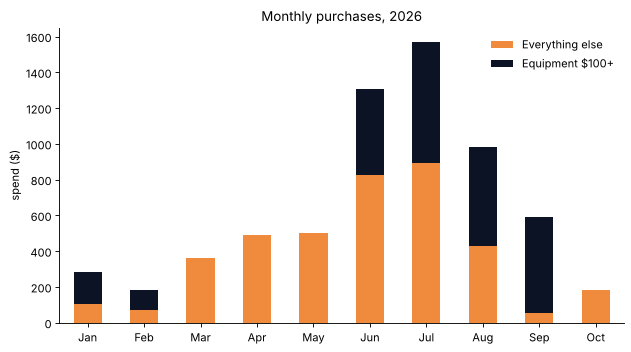

In [6]:
monthly = purchases.groupby("month").agg(items=("amount", "size"), spend=("amount", "sum"))
monthly["running_total"] = monthly["spend"].cumsum()
monthly["share"] = (monthly["spend"] / total).round(3)
print(monthly.round(2))

summer = monthly.loc["2026-06":"2026-08", "spend"].sum()
print(f"\nJune–August: ${summer:,.2f} = {summer / total:.0%} of the year's purchases")

# Stack equipment vs everything else so one-off buys don't hide the routine pattern
stack = (purchases.assign(kind=purchases["big_equipment"].map({True: "Equipment $100+", False: "Everything else"}))
         .pivot_table(index="month", columns="kind", values="amount", aggfunc="sum", fill_value=0))
stack.index = stack.index.strftime("%b")
ax = stack[["Everything else", "Equipment $100+"]].plot(kind="bar", stacked=True, color=[ORANGE, NAVY], figsize=(8, 4.5), rot=0)
ax.set_title("Monthly purchases, 2026"); ax.set_ylabel("spend ($)"); ax.set_xlabel("")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("spend_by_month.png", dpi=110); plt.show()

## Step 5 — Can spending be tied to a client?

This is the job-costing question: if purchases carry a client, the owner can compare what each client costs with what they pay.

                     items    spend  share
client                                    
Not recorded           108  5034.17   0.78
Wild Yough Glamping      7   380.70   0.06
DCLC (own business)      7   267.27   0.04
Client E                 2   229.56   0.04
Client D                 3   154.69   0.02
Client B                 3   142.83   0.02
Client A                 1    66.87   0.01
Pine & Paw Lodge         2    65.03   0.01
Client C                 1    63.74   0.01
Client F                 2    40.74   0.01
Client G                 1    12.50   0.00

No client: 108 of 137 items (79%), $5,034.17 (78% of spend)

Share of each category's spend with no client:
spend_category
Office & storage             0.95
Equipment & tools            0.91
Landscaping & garden         0.81
Repairs & maintenance        0.79
Events & party decor         0.76
Cleaning & guest supplies    0.40
Marketing & print            0.18
Name: amount, dtype: float64


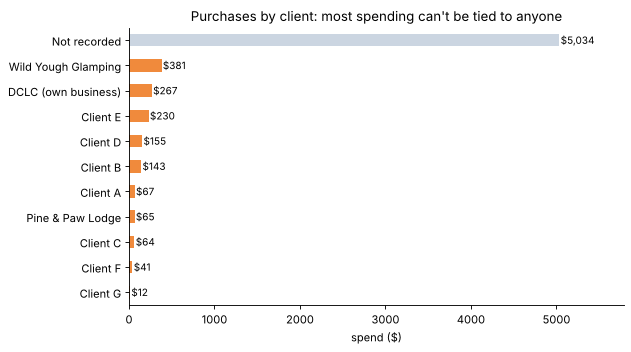

In [7]:
by_client = (purchases.groupby("client")
             .agg(items=("amount", "size"), spend=("amount", "sum"))
             .sort_values("spend", ascending=False))
by_client["share"] = (by_client["spend"] / total).round(3)
print(by_client.round(2))

untagged = purchases["client"].eq("Not recorded")
print(f"\nNo client: {untagged.sum()} of {len(purchases)} items ({untagged.mean():.0%}), "
      f"${purchases.loc[untagged, 'amount'].sum():,.2f} ({purchases.loc[untagged, 'amount'].sum() / total:.0%} of spend)")

# Which kinds of spending are missing a client?
print("\nShare of each category's spend with no client:")
print((purchases[untagged].groupby("spend_category")["amount"].sum()
       / purchases.groupby("spend_category")["amount"].sum()).fillna(0).sort_values(ascending=False).round(2))

plot = by_client["spend"].sort_values()
colors = [GREY if c == "Not recorded" else ORANGE for c in plot.index]
ax = plot.plot(kind="barh", color=colors, figsize=(8, 4.5))
for i, v in enumerate(plot):
    ax.text(v + 15, i, f"${v:,.0f}", va="center", fontsize=9)
ax.set_title("Purchases by client: most spending can't be tied to anyone"); ax.set_xlabel("spend ($)"); ax.set_ylabel("")
ax.set_xlim(0, plot.max() * 1.15)
plt.tight_layout(); plt.savefig("spend_by_client.png", dpi=110); plt.show()

## Step 6 — Trips, meals and fuel

In [8]:
# Mileage value uses the rate in effect on each trip date (from the log's Rates table)
rates = rates.sort_values("effective_from")
trips = trips.sort_values("date")
trips = pd.merge_asof(trips, rates, left_on="date", right_on="effective_from")
trips["destination"] = trips["destination"].fillna("Pine & Paw Lodge")   # arcade repair trip, per the meal entry the same day
trips["mileage_value"] = trips["miles"] * trips["cents_per_mile"] / 100

print(f"Trips: {len(trips)}, {trips['miles'].sum():.1f} miles, mileage value ${trips['mileage_value'].sum():,.2f} "
      f"at {trips['cents_per_mile'].iloc[0]}¢/mile  ({trips['date'].min():%b %d} – {trips['date'].max():%b %d})")
print(trips.groupby("destination").agg(trips=("miles", "size"), miles=("miles", "sum"))
      .sort_values("miles", ascending=False))

print(f"\nMeals: {len(meals)}, ${meals['amount'].sum():,.2f} total, "
      f"${(meals['amount'] * meals['deductible_pct'] / 100).sum():,.2f} at the logged {meals['deductible_pct'].iloc[0]}% rate")
print(meals["place"].str.replace("’", "'").str.replace("Arbys", "Arby's").value_counts().head(3))

print(f"\nFuel: {len(fuel)} fill-up logged — not enough to calculate miles per gallon or fuel cost per mile.")

Trips: 14, 227.2 miles, mileage value $172.67 at 76.0¢/mile  (Oct 02 – Oct 31)
                     trips  miles
destination                      
Pine & Paw Lodge         4   85.0
Client H                 2   34.0
Client J                 1   30.0
Multiple stops           1   30.0
Wild Yough Glamping      3   22.3
Bakery                   1   12.4
Client G                 1    9.2
Client I                 1    4.3

Meals: 16, $345.26 total, $172.63 at the logged 50% rate
place
Arby's       7
Baja         1
Arrowhead    1
Name: count, dtype: int64

Fuel: 1 fill-up logged — not enough to calculate miles per gallon or fuel cost per mile.


In [9]:
# How complete is each sheet? One row per sheet, share of the Jan–Oct period it covers
coverage = pd.DataFrame({
    "rows": [len(purchases), len(meals), len(trips), len(fuel)],
    "first": [d["date"].min().date() for d in (purchases, meals, trips, fuel)],
    "last":  [d["date"].max().date() for d in (purchases, meals, trips, fuel)],
}, index=["purchases", "meals", "trips", "fuel"])
print(coverage)
print("\nTrips logged before October:", (trips["date"] < "2026-10-01").sum(),
      "— yet meals show business visits back to June, so earlier mileage went unrecorded.")

           rows       first        last
purchases   137  2026-01-23  2026-10-19
meals        16  2026-06-01  2026-10-27
trips        14  2026-10-02  2026-10-31
fuel          1  2026-10-25  2026-10-25

Trips logged before October: 0 — yet meals show business visits back to June, so earlier mileage went unrecorded.


## Step 7 — Data-quality scorecard

                                     check       passing
                     Purchase has a client           21%
            Purchase has a useful category            7%
                    Purchase has a receipt           77%
               Vendor spelled consistently           93%
Trips logged for every month with activity 1 of 5 months
                   Fuel logged per fill-up     1 fill-up


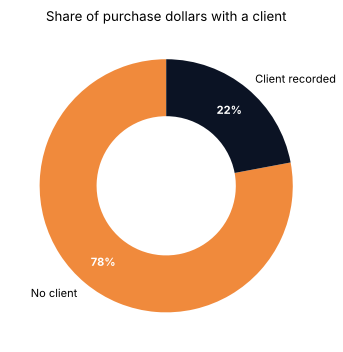

In [10]:
checks = pd.DataFrame({
    "check": ["Purchase has a client", "Purchase has a useful category", "Purchase has a receipt",
              "Vendor spelled consistently", "Trips logged for every month with activity", "Fuel logged per fill-up"],
    "passing": [
        f"{purchases['client'].ne('Not recorded').mean():.0%}",
        f"{(pd.read_csv('purchases_raw.csv')['category'] != 'Supplies').mean():.0%}",
        f"{purchases['has_receipt'].mean():.0%}",
        f"{(purchases['vendor'] == purchases['vendor_raw']).mean():.0%}",
        "1 of 5 months",                  # meals show business visits Jun–Oct; trips only in Oct
        "1 fill-up",
    ],
})
print(checks.to_string(index=False))

share = (purchases.assign(has_client=purchases["client"].ne("Not recorded"))
         .groupby("has_client")["amount"].sum().rename({True: "Client recorded", False: "No client"}))
fig, ax = plt.subplots(figsize=(4.5, 4.5))
_, _, pct = ax.pie(share, labels=share.index, colors=[ORANGE, NAVY], autopct="%1.0f%%", startangle=90,
                   pctdistance=0.78, wedgeprops={"width": 0.45}, textprops={"fontsize": 10})
for t in pct: t.set_color("white"); t.set_fontweight("bold")
ax.set_title("Share of purchase dollars with a client")
plt.tight_layout(); plt.savefig("client_coverage.png", dpi=110); plt.show()

## Findings and recommendations

| Question | Finding | Recommendation |
|---|---|---|
| Where the money goes | Equipment & tools is the largest category; a handful of one-off purchases (drone, pressure washer, ladder, trimmer, card terminal) make up a large share of the year. | Track big equipment separately from day-to-day supplies so routine costs are visible. |
| Seasonality | June–August is the busiest stretch for purchases; Jan–Feb and Sep–Oct are light. | Budget for a summer spike; buy landscaping and event supplies before June. |
| Events | Party and wedding decor is a real cost center, mostly with no client attached. | Treat event decorating as its own service line and price it to cover supplies. |
| Job costing | Most purchase dollars have no client, so cost per client can't be calculated. | Make *client* a required dropdown in the log form. |
| Data quality | Category is 93% "Supplies"; vendors are spelled several ways; Lowe's items have no receipts; trips start only in October; one fuel fill-up. | Use dropdowns for category and vendor, require a receipt photo, log trips and fuel at the time they happen. |

**Limitations:** about 10 months of data from one small business; purchases were entered after the fact from order history; trips cover one month only, so mileage findings are a snapshot; categories are rebuilt from item descriptions with keyword rules and may misplace a few items.